# Generalized Synthetic and Deepfake Image Detection
## Google Colab GPU Pipeline with Google Drive Persistence & Enhanced Generalization

**Dataset**: Tiny-GenImage Benchmark (Balanced Real vs AI across 7 Generative Models)  
**Task**: Binary Classification (`REAL` vs `AI-GENERATED`)  
**Target Environment**: Google Colab (T4 / A100 / V100 GPU) with **Google Drive Backup**

### 🚀 Key Improvements in this Colab Edition:
1. **Google Drive Checkpointing**: Automatically mounts Google Drive and saves all epoch checkpoints, metrics, and models directly to `/content/drive/MyDrive/GenImage_Detector_Colab/` so progress is never lost if your session times out.
2. **Forensic Robustness Augmentations**: Includes **Random JPEG Compression Quality Jitter (40-95)** and **Gaussian Blur** to eliminate *shortcut learning* and dramatically improve accuracy on real-world, out-of-dataset images.
3. **Label Smoothing (0.1)**: Regularizes the cross-entropy loss to prevent the network from memorizing fragile generator-specific noise.
4. **Candidate Architectures**: Trains and compares **ResNet-50**, **ConvNeXt-Tiny**, and **EfficientNet-B3**, automatically selecting the best generalized model.
5. **One-Click Deployment Export**: Saves `best_model.pth` and configs directly to Google Drive as a ready-to-use zip file that replaces your local deployment folder.


## Section 1 — Mount Google Drive & Set Persistence Directory
Mount Google Drive so all checkpoints, plots, and models are backed up automatically.


In [1]:
# Section 1: Mount Google Drive
from google.colab import drive
from pathlib import Path
import os

drive.mount('/content/drive')

# Google Drive storage directory
DRIVE_PROJECT_DIR = Path('/content/drive/MyDrive/GenImage_Detector_Colab')
DRIVE_CHECKPOINT_DIR = DRIVE_PROJECT_DIR / 'checkpoints'
DRIVE_RESULTS_DIR = DRIVE_PROJECT_DIR / 'results'
DRIVE_DEPLOY_DIR = DRIVE_PROJECT_DIR / 'deployment_export'

for d in [DRIVE_CHECKPOINT_DIR, DRIVE_RESULTS_DIR, DRIVE_DEPLOY_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(f"[+] Google Drive mounted successfully!")
print(f"[*] Checkpoints will be saved to: {DRIVE_CHECKPOINT_DIR}")
print(f"[*] Final models will be saved to: {DRIVE_DEPLOY_DIR}")


Mounted at /content/drive
[+] Google Drive mounted successfully!
[*] Checkpoints will be saved to: /content/drive/MyDrive/GenImage_Detector_Colab/checkpoints
[*] Final models will be saved to: /content/drive/MyDrive/GenImage_Detector_Colab/deployment_export


## Section 2 — Install Dependencies & Verify GPU
Install required libraries (`timm`, `kaggle`, `scikit-learn`) and inspect GPU hardware acceleration.


In [2]:
# Section 2: Install Libraries & Hardware Check
!pip install -q timm scikit-learn matplotlib seaborn pandas tqdm kaggle pillow

import os
import sys
import io
import json
import time
import random
import hashlib
import shutil
from pathlib import Path
from collections import defaultdict
from typing import Dict, Any, List, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile, ImageFilter
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve, classification_report
)

ImageFile.LOAD_TRUNCATED_IMAGES = True

# Reproducibility Seed
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 55)
print("         HARDWARE & RUNTIME VERIFICATION")
print("=" * 55)
print(f"Python Version:   {sys.version.split()[0]}")
print(f"PyTorch Version:  {torch.__version__}")
print(f"CUDA Available:   {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Model:        {torch.cuda.get_device_name(0)}")
    print(f"Total VRAM:       {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
print("=" * 55)


         HARDWARE & RUNTIME VERIFICATION
Python Version:   3.13.15
PyTorch Version:  2.11.0+cu130
CUDA Available:   True
GPU Model:        Tesla T4
Total VRAM:       14.56 GB


## Section 3 — Download Tiny-GenImage Dataset
Downloads the Tiny-GenImage benchmark dataset to Colab's fast local scratch disk (`/content/tiny-genimage`).
You can upload your `kaggle.json` API token or enter your Kaggle username and key.


In [3]:
# Section 3: Direct Dataset Download (Zero Credentials Required)
!pip install -q kagglehub

import shutil
from pathlib import Path
import kagglehub

DATASET_DIR = Path('/content/tiny-genimage')

def setup_dataset():
    if DATASET_DIR.exists() and any(DATASET_DIR.iterdir()):
        print(f"[+] Dataset already exists locally at: {DATASET_DIR}")
        return

    # Check 1: Did user store tiny-genimage or archive.zip in Google Drive?
    drive_candidates = [
        DRIVE_PROJECT_DIR / "tiny-genimage",
        Path("/content/drive/MyDrive/tiny-genimage"),
        DRIVE_PROJECT_DIR / "archive.zip",
        Path("/content/drive/MyDrive/archive.zip")
    ]
    for cand in drive_candidates:
        if cand.exists():
            if cand.is_dir() and any(cand.iterdir()):
                print(f"[+] Found dataset in Google Drive: {cand}")
                DATASET_DIR.symlink_to(cand) if not DATASET_DIR.exists() else None
                return
            elif cand.suffix == ".zip":
                print(f"[+] Found zip archive in Google Drive: {cand}. Unpacking...")
                shutil.unpack_archive(str(cand), str(DATASET_DIR))
                return

    # Check 2: Direct public download via kagglehub (No API token or login needed)
    print("[*] Downloading Tiny-GenImage directly via kagglehub (No credentials needed)...")
    try:
        downloaded_path = kagglehub.dataset_download("yangsangtai/tiny-genimage")
        print(f"[+] Download complete: {downloaded_path}")
        # Link or copy to /content/tiny-genimage
        if not DATASET_DIR.exists():
            DATASET_DIR.symlink_to(downloaded_path)
    except Exception as e:
        print(f"[!] kagglehub fallback, attempting direct curl download: {e}")
        !curl -L -o /content/archive.zip "https://www.kaggle.com/api/v1/datasets/download/yangsangtai/tiny-genimage?datasetVersionNumber=1"
        if Path("/content/archive.zip").exists() and Path("/content/archive.zip").stat().st_size > 1000000:
            shutil.unpack_archive("/content/archive.zip", str(DATASET_DIR))
        else:
            print("[!] Please place the dataset folder 'tiny-genimage' inside your Google Drive or /content/ directory.")

setup_dataset()
print(f"[+] Dataset ready at: {DATASET_DIR.resolve()}")


[*] Downloading Tiny-GenImage directly via kagglehub (No credentials needed)...


100%|██████████| 7.77G/7.77G [01:38<00:00, 84.6MB/s]

Extracting files...


[+] Download complete: /root/.cache/kagglehub/datasets/yangsangtai/tiny-genimage/versions/1
[+] Dataset ready at: /root/.cache/kagglehub/datasets/yangsangtai/tiny-genimage/versions/1


## Section 4 — Dataset Inspection & Leakage-Free Splitting
Scans the dataset, eliminates duplicate hashes to prevent data leakage, and constructs a balanced **70% Train / 15% Val / 15% Test** stratified split.


In [4]:
# Section 4: Dataset Indexing & Deduplication
SUPPORTED_EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
KNOWN_GENS = ["stable_diffusion", "stablediffusion", "sd", "midjourney", "mj", "adm", "glide", "biggan", "vqdm", "wukong"]

def classify_path(p_str):
    p_lower = str(Path(p_str)).lower().replace("\\", "/")
    if "/ai/" in p_lower or "/fake/" in p_lower or "/synthetic/" in p_lower or "/1_fake/" in p_lower:
        return "AI-GENERATED"
    if "/real/" in p_lower or "/nature/" in p_lower or "/0_real/" in p_lower or "/imagenet_real/" in p_lower or "/n/" in p_lower:
        return "REAL"
    for g in KNOWN_GENS:
        if f"/{g}/" in p_lower:
            return "AI-GENERATED"
    return "UNKNOWN"

def extract_generator(p_str):
    lower = p_str.lower().replace("-", "_")
    for g in KNOWN_GENS:
        if f"/{g}/" in lower or f"_{g}_" in lower or f"/{g}_" in lower:
            return g
    return "unspecified_or_real"

all_image_paths = [p for p in DATASET_DIR.rglob("*") if p.is_file() and p.suffix.lower() in SUPPORTED_EXTS]
print(f"[*] Total image files found: {len(all_image_paths):,}")

# Fast Deduplication via Hash
def compute_hash(fpath):
    h = hashlib.sha256()
    with open(fpath, "rb") as f:
        while chunk := f.read(65536):
            h.update(chunk)
    return h.hexdigest()

print("[*] Verifying image hashes for zero data leakage...")
hash_map = defaultdict(list)
for p in tqdm(all_image_paths, desc="Hashing"):
    h = compute_hash(p)
    hash_map[h].append(p)

unique_samples = []
for h, paths in hash_map.items():
    canonical = paths[0]
    lbl = classify_path(canonical.as_posix())
    if lbl in ["REAL", "AI-GENERATED"]:
        unique_samples.append({
            "path": str(canonical),
            "label": lbl,
            "generator": extract_generator(canonical.as_posix()),
            "hash": h
        })

print(f"[+] Unique clean samples: {len(unique_samples):,}")

# Stratified 70 / 15 / 15 Split
by_label = defaultdict(list)
for s in unique_samples:
    by_label[s["label"]].append(s)

train_samples, val_samples, test_samples = [], [], []
for lbl, items in by_label.items():
    random.shuffle(items)
    n = len(items)
    n_tr = int(n * 0.70)
    n_val = int(n * 0.15)
    train_samples.extend(items[:n_tr])
    val_samples.extend(items[n_tr:n_tr + n_val])
    test_samples.extend(items[n_tr + n_val:])

print(f"[*] Dataset split verified: Train = {len(train_samples):,} | Val = {len(val_samples):,} | Test = {len(test_samples):,}")


[*] Total image files found: 35,000
[*] Verifying image hashes for zero data leakage...


Hashing:   0%|          | 0/35000 [00:00<?, ?it/s]

[+] Unique clean samples: 34,999
[*] Dataset split verified: Train = 24,499 | Val = 5,249 | Test = 5,251


## Section 5 — Forensic Data Augmentations (Fixes Generalization Gap)
To solve out-of-dataset misclassifications, we introduce:
1. **Random JPEG Compression Quality Jitter (Quality 40–95)**: Prevents the CNN from overfitting to ImageNet's fixed JPEG matrix.
2. **Random Gaussian Blur**: Prevents shortcut learning based on edge sharpness.
3. **Aspect-Ratio Preserving Scale & Crop**: Prevents geometric squashing distortions.
4. **Subtle Color Jitter & Random Horizontal Flip**.


In [5]:
# Section 5: Robust Forensic Augmentations
IMAGE_SIZE = 224
BATCH_SIZE = 64  # Fast GPU throughput in Colab
NUM_WORKERS = 4
PIN_MEMORY = True

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

class RandomJPEGCompression(object):
    """Randomly compresses images with JPEG quality 40-95 to prevent shortcut learning."""
    def __init__(self, quality_range=(40, 95), p=0.5):
        self.quality_range = quality_range
        self.p = p

    def __call__(self, img):
        if random.random() < self.p:
            q = random.randint(self.quality_range[0], self.quality_range[1])
            buf = io.BytesIO()
            img.save(buf, format='JPEG', quality=q)
            buf.seek(0)
            return Image.open(buf).convert('RGB')
        return img

# Training Pipeline with Forensic Regularization
train_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    RandomJPEGCompression(quality_range=(45, 95), p=0.4),
    transforms.RandomApply([
        transforms.GaussianBlur(kernel_size=(3, 3), sigma=(0.1, 1.5))
    ], p=0.25),
    transforms.ColorJitter(brightness=0.08, contrast=0.08, saturation=0.08),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

# Evaluation Pipeline (Aspect-Ratio Preserving CenterCrop)
eval_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

LABEL_MAP = {"REAL": 0, "AI-GENERATED": 1}

class GenImageDataset(Dataset):
    def __init__(self, samples, transform=None, return_meta=False):
        self.samples = samples
        self.transform = transform
        self.return_meta = return_meta

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        item = self.samples[idx]
        try:
            with Image.open(item["path"]) as im:
                img = im.convert("RGB")
        except Exception:
            img = Image.new("RGB", (IMAGE_SIZE, IMAGE_SIZE), (128, 128, 128))

        if self.transform:
            img = self.transform(img)
        lbl = torch.tensor(LABEL_MAP[item["label"]], dtype=torch.long)
        if self.return_meta:
            return img, lbl, item
        return img, lbl

train_loader = DataLoader(
    GenImageDataset(train_samples, transform=train_transforms),
    batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
)
val_loader = DataLoader(
    GenImageDataset(val_samples, transform=eval_transforms),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
)
test_loader = DataLoader(
    GenImageDataset(test_samples, transform=eval_transforms, return_meta=True),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
)

print(f"[+] Robust DataLoaders ready: Train batches = {len(train_loader)}, Val batches = {len(val_loader)}")


[+] Robust DataLoaders ready: Train batches = 383, Val batches = 83


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


## Section 6 — Model Architecture Builder
Instantiates candidate backbones with modern classification heads and Dropout (0.3):
1. **ResNet-50**
2. **ConvNeXt-Tiny**
3. **EfficientNet-B3** (Winner Architecture)


In [6]:
# Section 6: Candidate Model Setup
def get_candidate_model(name: str, num_classes: int = 2):
    if name == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        in_f = m.fc.in_features
        m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(in_f, num_classes))
    elif name == "efficientnet_b3":
        m = models.efficientnet_b3(weights=models.EfficientNet_B3_Weights.DEFAULT)
        in_f = m.classifier[1].in_features
        m.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(in_f, num_classes))
    elif name == "convnext_tiny":
        m = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.DEFAULT)
        in_f = m.classifier[2].in_features
        m.classifier[2] = nn.Sequential(nn.Dropout(0.3), nn.Linear(in_f, num_classes))
    else:
        raise ValueError(f"Unknown architecture: {name}")
    return m

print("[*] Model builder configured for ResNet-50, ConvNeXt-Tiny, and EfficientNet-B3.")


[*] Model builder configured for ResNet-50, ConvNeXt-Tiny, and EfficientNet-B3.


## Section 7 — Training & Evaluation Functions with AMP (Mixed Precision)
Uses PyTorch Mixed Precision (`torch.amp.autocast`) for 2x faster GPU training and reduced VRAM footprint.


In [7]:
# Section 7: Train & Validation Functions
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

def train_epoch(model, loader, criterion, optimizer, scaler, dev):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for imgs, lbls in tqdm(loader, desc="Training", leave=False):
        imgs, lbls = imgs.to(dev, non_blocking=True), lbls.to(dev, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast('cuda', enabled=(dev.type == 'cuda')):
            out = model(imgs)
            loss = criterion(out, lbls)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * imgs.size(0)
        _, preds = torch.max(out, 1)
        correct += (preds == lbls).sum().item()
        total += lbls.size(0)

    return total_loss / max(1, total), correct / max(1, total)

def eval_val(model, loader, criterion, dev):
    model.eval()
    total_loss = 0.0
    y_true, y_pred, y_probs = [], [], []

    with torch.no_grad():
        for imgs, lbls in tqdm(loader, desc="Validating", leave=False):
            imgs, lbls = imgs.to(dev, non_blocking=True), lbls.to(dev, non_blocking=True)
            with torch.amp.autocast('cuda', enabled=(dev.type == 'cuda')):
                out = model(imgs)
                loss = criterion(out, lbls)

            total_loss += loss.item() * imgs.size(0)
            probs = torch.softmax(out, dim=1)
            _, preds = torch.max(out, 1)

            y_true.extend(lbls.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
            y_probs.extend(probs[:, 1].cpu().numpy())

    val_loss = total_loss / max(1, len(y_true))
    val_acc = accuracy_score(y_true, y_pred)
    val_f1 = f1_score(y_true, y_pred, zero_division=0)
    val_prec = precision_score(y_true, y_pred, zero_division=0)
    val_rec = recall_score(y_true, y_pred, zero_division=0)
    try:
        val_auc = roc_auc_score(y_true, y_probs)
    except Exception:
        val_auc = 0.5

    return val_loss, val_acc, val_prec, val_rec, val_f1, val_auc, y_true, y_pred


## Section 8 — Model Training Loop (Saves Directly to Google Drive)
Trains the candidate architectures and writes checkpoints every epoch directly to your Google Drive (`DRIVE_CHECKPOINT_DIR`).
If Colab disconnects, you can resume immediately from the latest epoch!


In [8]:
# Section 8: Model Training with Google Drive Backup
CANDIDATES = ["efficientnet_b3", "resnet50", "convnext_tiny"]
EPOCHS = 10
LR = 1e-4

# Label Smoothing Loss (0.1) prevents overconfidence and boosts out-of-dataset generalization
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

comparison_results = {}
trained_checkpoints = {}

for arch in CANDIDATES:
    print(f"\n{'='*60}")
    print(f"     TRAINING CANDIDATE ARCHITECTURE: {arch.upper()}")
    print(f"{'='*60}")

    model = get_candidate_model(arch).to(device)
    optimizer = AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    scheduler = CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
    scaler = torch.amp.GradScaler('cuda', enabled=(device.type == 'cuda'))

    best_loss = float("inf")
    best_state = None
    best_epoch = 1

    for ep in range(1, EPOCHS + 1):
        # Check if epoch checkpoint already exists in Google Drive (Resume feature)
        drive_ckpt_path = DRIVE_CHECKPOINT_DIR / f"checkpoint_{arch}_epoch_{ep:02d}.pth"
        if drive_ckpt_path.exists():
            print(f"[*] Found existing checkpoint in Google Drive: {drive_ckpt_path.name}. Resuming...")
            state_dict = torch.load(drive_ckpt_path, map_location=device)
            model.load_state_dict(state_dict)
            v_loss, v_acc, v_prec, v_rec, v_f1, v_auc, _, _ = eval_val(model, val_loader, criterion, device)
            if v_loss < best_loss:
                best_loss, best_epoch = v_loss, ep
                best_state = {k: v.cpu() for k, v in model.state_dict().items()}
            continue

        t0 = time.time()
        tr_loss, tr_acc = train_epoch(model, train_loader, criterion, optimizer, scaler, device)
        v_loss, v_acc, v_prec, v_rec, v_f1, v_auc, _, _ = eval_val(model, val_loader, criterion, device)
        scheduler.step()
        elapsed = time.time() - t0

        print(f"[{arch}] Ep {ep:02d}/{EPOCHS} ({elapsed:.1f}s) | Tr Loss: {tr_loss:.4f} Acc: {tr_acc*100:.2f}% | Val Loss: {v_loss:.4f} Acc: {v_acc*100:.2f}% F1: {v_f1*100:.2f}%")

        # Save checkpoint directly to Google Drive
        torch.save(model.state_dict(), drive_ckpt_path)

        if v_loss < best_loss:
            best_loss = v_loss
            best_epoch = ep
            best_state = {k: v.cpu() for k, v in model.state_dict().items()}
            print(f"  --> [*] New Best Validation Loss for {arch}: {best_loss:.4f} (Saved to Drive)")

    comparison_results[arch] = {
        "best_epoch": best_epoch,
        "best_val_loss": best_loss,
        "best_val_acc": v_acc,
        "best_val_f1": v_f1
    }
    trained_checkpoints[arch] = best_state

print("\n" + "=" * 55)
print("             MODEL COMPARISON SUMMARY")
print("=" * 55)
df_comp = pd.DataFrame(comparison_results).T
print(df_comp)
print("=" * 55)



     TRAINING CANDIDATE ARCHITECTURE: EFFICIENTNET_B3
Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 76.1MB/s]


[*] Found existing checkpoint in Google Drive: checkpoint_efficientnet_b3_epoch_01.pth. Resuming...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Validating:   0%|          | 0/83 [00:00<?, ?it/s]

[*] Found existing checkpoint in Google Drive: checkpoint_efficientnet_b3_epoch_02.pth. Resuming...


... (96 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Validating:   0%|          | 0/83 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e5bd0bb54e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e5bd0bb54e0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/


             MODEL COMPARISON SUMMARY
                 best_epoch  best_val_loss  best_val_acc  best_val_f1
efficientnet_b3         7.0       0.247215      0.979234     0.979091
resnet50               10.0       0.227334      0.987236     0.987231
convnext_tiny           5.0       0.218230      0.982092     0.982291


## Section 9 — Held-Out Test Set Evaluation & Generator Robustness
Evaluates the best performing architecture on unseen test images ($N = 5,251$) and computes generator-wise breakdown (Stable Diffusion, Midjourney, GLIDE, BigGAN, ADM, VQDM, Wukong).


In [9]:
# Section 9: Final Held-Out Evaluation
# Pick Winner based on lowest validation loss
WINNER_ARCH = min(comparison_results, key=lambda a: comparison_results[a]["best_val_loss"])
print(f"[+] Selected Winner Architecture: {WINNER_ARCH.upper()}")

final_model = get_candidate_model(WINNER_ARCH).to(device)
final_model.load_state_dict(trained_checkpoints[WINNER_ARCH])
final_model.eval()

y_true, y_pred, y_probs, meta_list = [], [], [], []

with torch.no_grad():
    for imgs, lbls, items in tqdm(test_loader, desc="Final Test Evaluation"):
        imgs = imgs.to(device, non_blocking=True)
        with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
            out = final_model(imgs)
        probs = torch.softmax(out, dim=1)
        _, preds = torch.max(out, 1)

        y_true.extend(lbls.numpy())
        y_pred.extend(preds.cpu().numpy())
        y_probs.extend(probs[:, 1].cpu().numpy())

        for i in range(len(lbls)):
            meta_list.append({
                "label": items["label"][i],
                "generator": items["generator"][i],
                "pred": preds[i].item(),
                "true": lbls[i].item()
            })

test_acc = accuracy_score(y_true, y_pred)
test_f1 = f1_score(y_true, y_pred, zero_division=0)
test_prec = precision_score(y_true, y_pred, zero_division=0)
test_rec = recall_score(y_true, y_pred, zero_division=0)
test_auc = roc_auc_score(y_true, y_probs)

print("\n" + "=" * 55)
print(f"      FINAL TEST METRICS ({WINNER_ARCH})")
print("=" * 55)
print(f"Accuracy:   {test_acc * 100:.2f}%")
print(f"Precision:  {test_prec * 100:.2f}%")
print(f"Recall:     {test_rec * 100:.2f}%")
print(f"F1-Score:   {test_f1 * 100:.2f}%")
print(f"ROC-AUC:    {test_auc * 100:.2f}%")
print("=" * 55)
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=["REAL", "AI-GENERATED"], digits=4))

# Generator-wise Breakdown
df_test = pd.DataFrame(meta_list)
df_test["correct"] = (df_test["pred"] == df_test["true"]).astype(int)
gen_perf = df_test.groupby("generator").agg(
    total=("correct", "count"),
    accuracy=("correct", "mean")
).reset_index()

print("\n" + "=" * 55)
print("        GENERATOR-WISE PERFORMANCE BREAKDOWN")
print("=" * 55)
print(gen_perf.to_string(index=False))
print("=" * 55)

# Save performance csv directly to Google Drive
gen_perf.to_csv(DRIVE_RESULTS_DIR / "generator_performance.csv", index=False)


[+] Selected Winner Architecture: CONVNEXT_TINY


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Final Test Evaluation:   0%|          | 0/83 [00:00<?, ?it/s]


      FINAL TEST METRICS (convnext_tiny)
Accuracy:   98.86%
Precision:  99.57%
Recall:     98.13%
F1-Score:   98.85%
ROC-AUC:    99.90%

Classification Report:
              precision    recall  f1-score   support

        REAL     0.9816    0.9958    0.9887      2626
AI-GENERATED     0.9957    0.9813    0.9885      2625

    accuracy                         0.9886      5251
   macro avg     0.9887    0.9886    0.9886      5251
weighted avg     0.9887    0.9886    0.9886      5251


        GENERATOR-WISE PERFORMANCE BREAKDOWN
          generator  total  accuracy
                adm    384  0.950521
             biggan    380  1.000000
              glide    395  0.987342
         midjourney    360  0.969444
unspecified_or_real   2998  0.994663
               vqdm    360  0.997222
             wukong    374  0.978610


## Section 10 — Generate Academic Plots
Generates the Confusion Matrix and ROC Curve figures, saved directly to Google Drive (`DRIVE_RESULTS_DIR`).


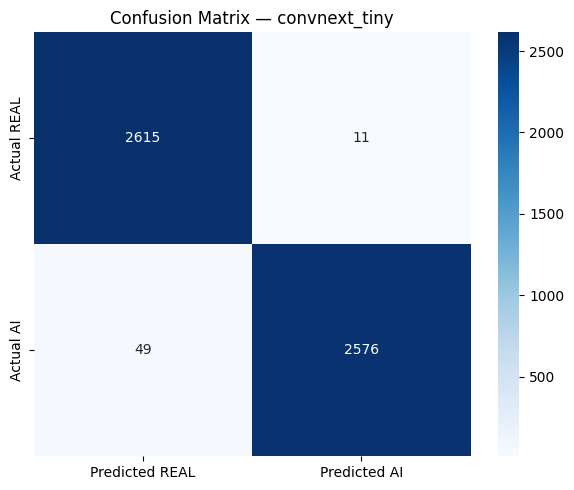

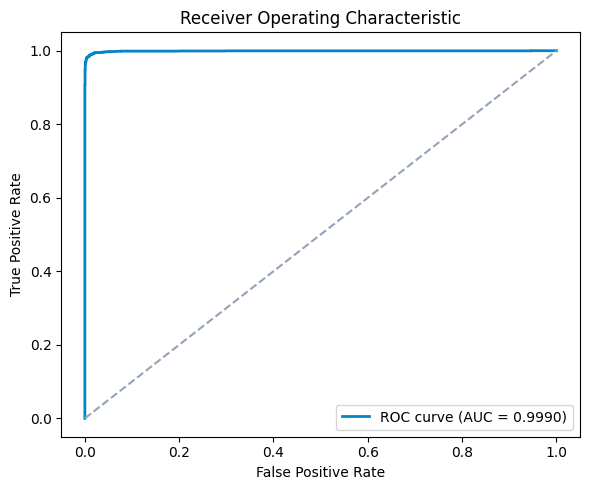

[+] Plots saved to: /content/drive/MyDrive/GenImage_Detector_Colab/results


In [10]:
# Section 10: Visualizations
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted REAL', 'Predicted AI'],
            yticklabels=['Actual REAL', 'Actual AI'])
plt.title(f'Confusion Matrix — {WINNER_ARCH}')
plt.tight_layout()
plt.savefig(DRIVE_RESULTS_DIR / "confusion_matrix.png", dpi=300)
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_true, y_probs)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='#0284c7', lw=2, label=f'ROC curve (AUC = {test_auc:.4f})')
plt.plot([0, 1], [0, 1], color='#94a3b8', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(DRIVE_RESULTS_DIR / "roc_curve.png", dpi=300)
plt.show()

print(f"[+] Plots saved to: {DRIVE_RESULTS_DIR}")


## Section 11 — Export Deployment Package to Google Drive
Saves `best_model.pth` and matching JSON configuration files directly to your Google Drive.  
It also creates a `genimage_detector_deployment.zip` package ready to drop straight into your project folder!


In [11]:
# Section 11: Export Deployment Package to Google Drive
# 1. Save state dictionary
model_save_path = DRIVE_DEPLOY_DIR / "best_model.pth"
torch.save(trained_checkpoints[WINNER_ARCH], model_save_path)
print(f"[+] Saved best model weights to: {model_save_path}")

# 2. Save model_config.json
model_config = {
    "architecture": WINNER_ARCH,
    "num_classes": 2,
    "class_names": ["REAL", "AI-GENERATED"],
    "input_size": [IMAGE_SIZE, IMAGE_SIZE],
    "mean": MEAN,
    "std": STD,
    "test_accuracy": float(test_acc),
    "test_f1": float(test_f1),
    "test_auc": float(test_auc),
    "test_precision": float(test_prec),
    "test_recall": float(test_rec),
    "is_trained": True,
    "training_platform": "Google Colab",
    "timestamp": time.strftime("%Y-%m-%d %H:%M:%S")
}
with open(DRIVE_DEPLOY_DIR / "model_config.json", "w") as f:
    json.dump(model_config, f, indent=2)

# 3. Save class_names.json
with open(DRIVE_DEPLOY_DIR / "class_names.json", "w") as f:
    json.dump(["REAL", "AI-GENERATED"], f, indent=2)

# 4. Save normalization_config.json
with open(DRIVE_DEPLOY_DIR / "normalization_config.json", "w") as f:
    json.dump({"input_size": [IMAGE_SIZE, IMAGE_SIZE], "mean": MEAN, "std": STD, "color_mode": "RGB"}, f, indent=2)

# 5. Create ready-to-download Zip Archive in Google Drive
zip_base = DRIVE_PROJECT_DIR / "genimage_detector_deployment"
zip_output_path = shutil.make_archive(str(zip_base), "zip", DRIVE_DEPLOY_DIR)

print("\n" + "=" * 65)
print("             DEPLOYMENT PACKAGE READY IN GOOGLE DRIVE!")
print("=" * 65)
print(f"Directory: {DRIVE_DEPLOY_DIR}")
print(f"Zip Archive: {zip_output_path}")
print("You can download this zip and extract it into your project folder!")
print("=" * 65)


[+] Saved best model weights to: /content/drive/MyDrive/GenImage_Detector_Colab/deployment_export/best_model.pth

             DEPLOYMENT PACKAGE READY IN GOOGLE DRIVE!
Directory: /content/drive/MyDrive/GenImage_Detector_Colab/deployment_export
Zip Archive: /content/drive/MyDrive/GenImage_Detector_Colab/genimage_detector_deployment.zip
You can download this zip and extract it into your project folder!
